# 03 · Les couleurs des Pokémon à partir de leurs images

Dans PokéAPI chaque Pokémon a **une seule couleur officielle** (`couleur` dans la table maître). C'est pratique mais très grossier : Dracaufeu est « rouge » alors qu'il est orange avec du bleu et du crème.

L'idée ici c'est de repartir des **images officielles** (artwork) et de calculer nous-mêmes :
- combien de couleurs « importantes » a chaque Pokémon ;
- quelle est sa couleur dominante ;
- quelle part du corps prend chaque couleur.

Pour ça on utilise le **k-means** du TP2, mais sur les pixels d'une image : chaque pixel est un point (R, V, B) et on regroupe les pixels qui ont une couleur proche. Le centre de chaque groupe, c'est une couleur de la palette du Pokémon.

La démarche : on découvre d'abord les images, on enlève le fond, on choisit le nombre de groupes du k-means sur quelques exemples, on fusionne les nuances d'une même couleur, on enlève le contour noir du dessin, puis on applique tout ça aux 1 025 Pokémon. À la fin on compare avec la couleur officielle et on regarde l'évolution au fil des générations.

In [1]:
from pathlib import Path
import colorsys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

IMG = Path("../data/raw/sprites/official_artwork")
OUT = Path("../data/processed")
table = pd.read_csv(OUT / "table_maitre.csv", index_col="dex")
nom = table["nom_fr"]

## 1. Découverte des images

In [2]:
fichiers = sorted(IMG.glob("*.png"), key=lambda p: int(p.stem))
print(len(fichiers), "images")
infos = []
for p in fichiers:
    im = Image.open(p)
    infos.append((int(p.stem), im.size, im.mode))
infos = pd.DataFrame(infos, columns=["dex", "taille", "mode"]).set_index("dex")
print(infos["taille"].value_counts())
print(infos["mode"].value_counts())

1025 images


taille
(475, 475)    1025
Name: count, dtype: int64
mode
RGBA    1025
Name: count, dtype: int64


Les 1 025 images sont toutes au même format : 475 × 475 pixels, en mode RGBA (rouge, vert, bleu + transparence).

In [3]:
# est-ce qu'il manque des numéros ?
set(range(1, 1026)) - set(infos.index)

set()

Il ne manque aucun numéro.

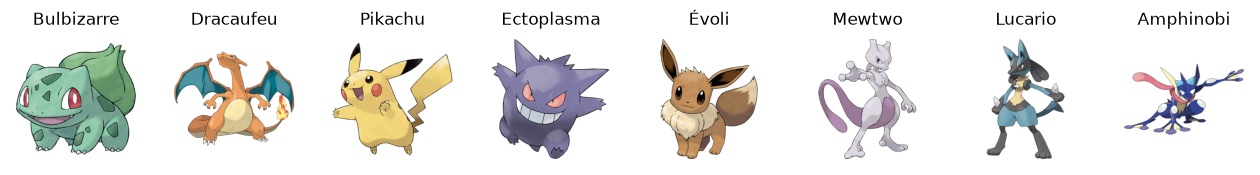

In [4]:
exemples = [1, 6, 25, 94, 133, 150, 448, 658]
fig, axes = plt.subplots(1, len(exemples), figsize=(16, 2.5))
for ax, d in zip(axes, exemples):
    ax.imshow(Image.open(IMG / f"{d}.png"))
    ax.set_title(nom[d])
    ax.axis("off")
plt.show()

On voit que tous les dessins ont le même style : un fond transparent, des aplats de couleur avec des ombres, et **un contour sombre** autour du Pokémon et de ses détails. On reviendra sur ce contour plus bas.

Le fond transparent, c'est le 4e canal (alpha) du mode RGBA. Un pixel avec alpha = 0 est invisible, il ne faut pas le compter comme une couleur. On regarde quelle part de l'image est transparente, et s'il y a des valeurs d'alpha entre 0 et 255 (les bords adoucis).

In [5]:
def alpha(d):
    return np.asarray(Image.open(IMG / f"{d}.png").convert("RGBA"))[..., 3]

a = alpha(25)
print("Pikachu : part de pixels totalement transparents =", round((a == 0).mean(), 3))
print("part de pixels semi-transparents (entre 1 et 254) =", round(((a > 0) & (a < 255)).mean(), 4))

Pikachu : part de pixels totalement transparents = 0.648
part de pixels semi-transparents (entre 1 et 254) = 0.0153


Sur Pikachu, 65 % de l'image est totalement transparente, et 1,5 % des pixels sont semi-transparents : ce sont les bords adoucis du dessin, dont la couleur est mélangée avec le fond.

Du coup on décide de ne garder que les pixels **assez opaques, avec alpha ≥ 128** (la moitié de 255). Ça enlève le fond et la plupart des bords adoucis, qui ne sont pas de vraies couleurs du Pokémon. On perd un peu de bord, mais c'est très peu de pixels.

In [6]:
SEUIL_ALPHA = 128

# part de pixels visibles sur toutes les images
part_visible = pd.Series({d: (alpha(d) >= SEUIL_ALPHA).mean() for d in infos.index}, name="part_visible")
part_visible.describe()

count    1025.000000
mean        0.313141
std         0.092918
min         0.097711
25%         0.248049
50%         0.303291
75%         0.368182
max         0.636242
Name: part_visible, dtype: float64

In [7]:
pd.concat([part_visible, nom], axis=1).sort_values("part_visible").iloc[[0, 1, 2, -3, -2, -1]]

,part_visible,nom_fr
973,0.097711,Flamenroule
283,0.102564,Arakdo
960,0.105316,Taupikeau
517,0.624625,Munna
577,0.627918,Nucléos
101,0.636242,Électrode


En moyenne le Pokémon occupe 31 % de l'image. Ça va de 10 % pour les Pokémon fins ou allongés (Flamenroule, Arakdo, Taupikeau) à 64 % pour les Pokémon ronds (Électrode, Nucléos, Munna). Même dans le pire cas il reste plus de 20 000 pixels visibles.

Faire un k-means sur ~70 000 pixels pour chacun des 1 025 Pokémon serait très long. Comme on cherche juste les grandes zones de couleur, on décide de **tirer au hasard 3 000 pixels visibles par image** : c'est largement assez pour qu'une couleur qui couvre quelques pour cent du corps soit bien représentée (5 % de 3 000 = 150 pixels). On fixe la graine du hasard pour que les résultats soient les mêmes à chaque exécution, et on donne à **chaque Pokémon son propre tirage** (la graine combinée à son numéro) : comme ça, un Pokémon a toujours les mêmes 3 000 pixels, même si on relance une seule cellule ou si on ajoute un exemple avant la boucle sur les 1 025 Pokémon.

In [8]:
N_PIXELS = 3000
SEED = 0

def pixels(d, n=N_PIXELS):
    # un générateur par Pokémon, à partir de la graine et du numéro : un Pokémon a toujours
    # les mêmes pixels, quel que soit l'ordre dans lequel on exécute les cellules
    rng = np.random.default_rng([SEED, d])
    arr = np.asarray(Image.open(IMG / f"{d}.png").convert("RGBA")).reshape(-1, 4)
    vis = arr[arr[:, 3] >= SEUIL_ALPHA, :3]
    if len(vis) > n:
        vis = vis[rng.choice(len(vis), n, replace=False)]
    return vis.astype(float)

pixels(25).shape

(3000, 3)

### Ce qu'on a fait et pourquoi

**1. Le canal alpha pour enlever le fond.** Les images sont en RGBA : le fond est transparent. On ne garde que les pixels assez opaques (alpha ≥ 128, la moitié) parce qu'un pixel transparent n'est pas une couleur du Pokémon, et que les bords à moitié transparents ont une couleur mélangée avec le fond. Couper à la moitié, c'est le choix le plus neutre : on garde ce qui est « plus Pokémon que fond ».

**2. Un échantillon de pixels plutôt que tous.** On tire 3 000 pixels visibles au hasard par image au lieu de les prendre tous, sinon le k-means sur 1 025 images serait très long. Comme on cherche les grandes zones de couleur, un échantillon suffit : une couleur qui couvre quelques pour cent du corps a encore une centaine de pixels. On fixe la graine pour que les résultats ne changent pas d'une exécution à l'autre. Au départ on utilisait un seul générateur pour tout le notebook : les pixels tirés pour un Pokémon dépendaient alors de tous les tirages faits avant lui, et relancer une cellule au milieu (ou ajouter un exemple) changeait les résultats. On a donc donné à chaque Pokémon son propre générateur (graine + numéro).

## 2. Combien de groupes pour le k-means ?

Comme au TP2, on fait tourner le k-means pour k = 2 à 12 sur trois exemples et on regarde :
- **l'inertie** (somme des distances au centre) : elle baisse toujours quand k augmente, on cherche le « coude » où elle arrête de baisser beaucoup ;
- **la silhouette** : entre -1 et 1, plus elle est haute plus les groupes sont bien séparés.

On prend Pikachu (simple, jaune), Dracaufeu (plusieurs couleurs) et Ectoplasma (presque une seule couleur).

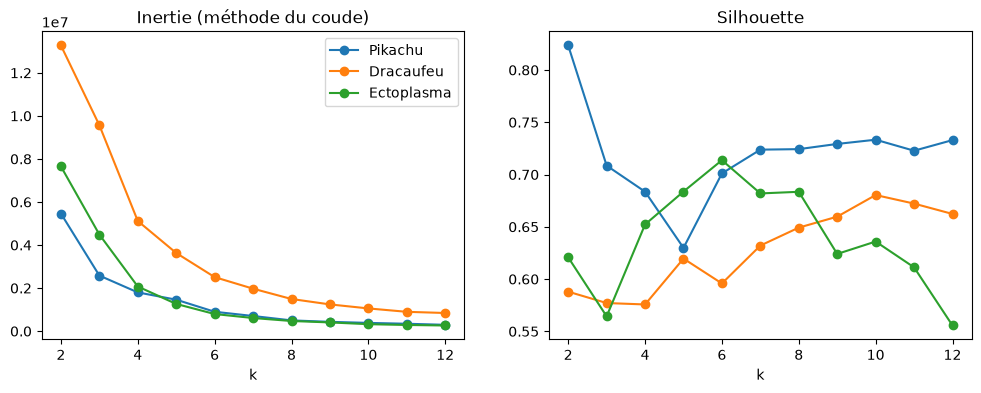

In [9]:
ks = range(2, 13)
res = {}
for d in [25, 6, 94]:
    X = pixels(d)
    inert, sil = [], []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=3, random_state=SEED).fit(X)
        inert.append(km.inertia_)
        sil.append(silhouette_score(X, km.labels_))
    res[nom[d]] = (inert, sil)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for n, (inert, sil) in res.items():
    axes[0].plot(list(ks), inert, marker="o", label=n)
    axes[1].plot(list(ks), sil, marker="o", label=n)
axes[0].set(title="Inertie (méthode du coude)", xlabel="k")
axes[1].set(title="Silhouette", xlabel="k")
axes[0].legend(); plt.show()

In [10]:
pd.DataFrame({n: sil for n, (_, sil) in res.items()}, index=list(ks)).round(3)

,Pikachu,Dracaufeu,Ectoplasma
2,0.823,0.588,0.621
3,0.709,0.577,0.564
4,0.684,0.576,0.652
5,0.630,0.620,0.684
6,0.701,0.596,0.714
7,0.724,0.632,0.682
8,0.724,0.649,0.684
9,0.729,0.660,0.624
10,0.733,0.680,0.636
11,0.723,0.672,0.611


L'inertie baisse beaucoup jusqu'à k = 4 environ puis de moins en moins, mais il n'y a pas de coude net. Et la silhouette ne donne pas le même k selon le Pokémon : k = 2 pour Pikachu (0,82), k = 6 pour Ectoplasma (0,71), k = 10 pour Dracaufeu (0,68). Il n'y a donc **pas un k qui marche pour tout le monde**.

Chercher le meilleur k pour chacun des 1 025 Pokémon serait long et pas très stable. On choisit plutôt de prendre **un k assez grand pour tout le monde, k = 8**, pour être sûr de ne rater aucune couleur même chez les Pokémon chargés, et de **regrouper ensuite les nuances trop proches** (partie 3). Avec k = 8, la silhouette est déjà bonne pour les trois exemples (0,65 à 0,72).

On voit ce que ça donne sur Dracaufeu, avec k = 3 et k = 8. Chaque barre est une couleur, sa largeur = la part des pixels.

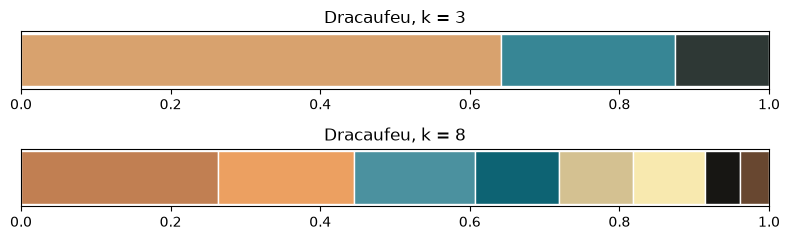

In [11]:
K = 8

def palette(X, k=K):
    km = KMeans(n_clusters=k, n_init=3, random_state=SEED).fit(X)
    parts = np.bincount(km.labels_, minlength=k) / len(X)
    return km.cluster_centers_, parts, km.labels_

def dessine(ax, centres, parts, titre=""):
    x = 0
    for i in np.argsort(-parts):
        ax.barh(0, parts[i], left=x, color=np.clip(centres[i], 0, 255) / 255, edgecolor="white")
        x += parts[i]
    ax.set(xlim=(0, 1), yticks=[], title=titre)

X = pixels(6)
fig, axes = plt.subplots(2, 1, figsize=(8, 2.5))
for ax, k in zip(axes, [3, 8]):
    c, p, _ = palette(X, k)
    dessine(ax, c, p, f"Dracaufeu, k = {k}")
plt.tight_layout(); plt.show()

Avec k = 3 le k-means mélange des couleurs différentes. Avec k = 8 on retrouve bien l'orange, le bleu des ailes, le crème du ventre et le contour noir, mais l'orange, le bleu et le crème sont coupés en deux nuances (clair / ombre). C'est ce qu'on règle maintenant.

## 3. Fusionner les nuances d'une même couleur

Avec k = 8, le k-means découpe souvent une même couleur en plusieurs nuances : la partie éclairée, la partie dans l'ombre… Bulbizarre aurait alors 4 ou 5 « couleurs » qui sont toutes du vert. Ce n'est pas ce qu'on veut compter.

Donc après le k-means, on regroupe les centres trop proches. Pour mesurer la distance entre deux couleurs, on passe dans l'**espace Lab** : c'est un espace fait pour que la distance corresponde à peu près à la différence que voit l'œil (en RGB, deux couleurs à la même distance peuvent paraître très proches ou très différentes). Dans Lab, **L\*** c'est la clarté (0 = noir, 100 = blanc), et a\*, b\* donnent la teinte. La distance entre deux couleurs s'appelle le **ΔE** : autour de 2 on voit à peine la différence, au-delà de 20-30 ce sont des couleurs nettement différentes.

On regroupe les centres avec une classification hiérarchique (lien moyen, comme la CAH du TP2) coupée à un seuil de ΔE. La couleur d'un groupe fusionné est la moyenne de ses nuances, pondérée par leur part. On essaie trois seuils sur quatre exemples.

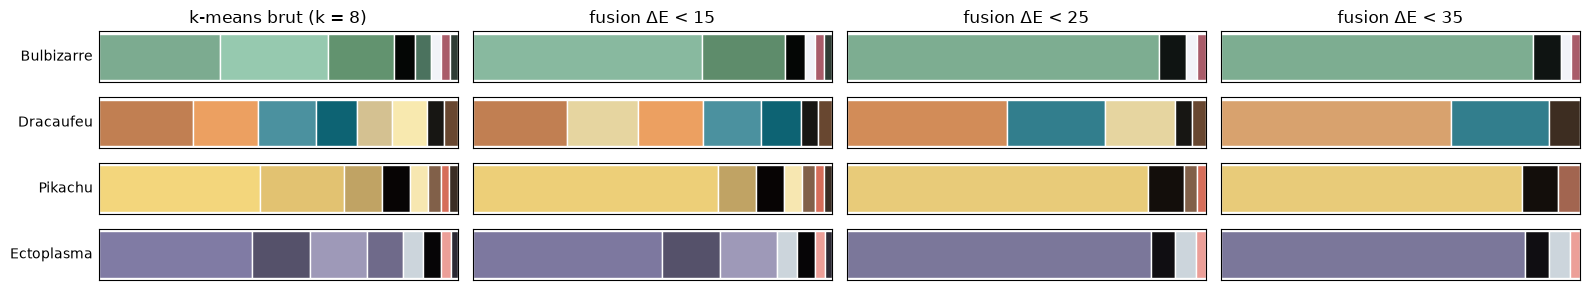

,ΔE < 15,ΔE < 25,ΔE < 35
Bulbizarre,6,4,4
Dracaufeu,7,5,3
Pikachu,7,4,3
Ectoplasma,7,4,4


In [12]:
def rgb_vers_lab(rgb):
    # rgb entre 0 et 255 -> Lab (illuminant D65), formule standard
    c = np.asarray(rgb, dtype=float) / 255
    c = np.where(c > 0.04045, ((c + 0.055) / 1.055) ** 2.4, c / 12.92)
    M = np.array([[0.4124, 0.3576, 0.1805], [0.2126, 0.7152, 0.0722], [0.0193, 0.1192, 0.9505]])
    xyz = c @ M.T / np.array([0.95047, 1.0, 1.08883])
    f = np.where(xyz > 0.008856, np.cbrt(xyz), 7.787 * xyz + 16 / 116)
    return np.stack([116 * f[..., 1] - 16, 500 * (f[..., 0] - f[..., 1]), 200 * (f[..., 1] - f[..., 2])], axis=-1)

def fusion(centres, parts, seuil):
    # renvoie les couleurs fusionnées (de la plus grande à la plus petite), leurs parts,
    # et pour chaque groupe du k-means le numéro de la couleur fusionnée où il est rangé
    groupes = AgglomerativeClustering(n_clusters=None, distance_threshold=seuil,
                                      linkage="average").fit_predict(rgb_vers_lab(centres))
    uniques = np.unique(groupes)
    nc = np.array([(centres[groupes == g] * parts[groupes == g, None]).sum(0) / parts[groupes == g].sum() for g in uniques])
    np_ = np.array([parts[groupes == g].sum() for g in uniques])
    ordre = np.argsort(-np_)
    rang = np.empty(len(uniques), dtype=int); rang[ordre] = np.arange(len(uniques))
    return nc[ordre], np_[ordre], rang[np.searchsorted(uniques, groupes)]

ex = [1, 6, 25, 94]
pal_ex = {d: palette(pixels(d)) for d in ex}
seuils = [15, 25, 35]
fig, axes = plt.subplots(len(ex), 1 + len(seuils), figsize=(16, 3))
for ligne, d in zip(axes, ex):
    c, p, _ = pal_ex[d]
    dessine(ligne[0], c, p)
    for ax, s in zip(ligne[1:], seuils):
        fc, fp, _ = fusion(c, p, s)
        dessine(ax, fc, fp)
    ligne[0].set_ylabel(nom[d], rotation=0, ha="right", va="center")
    for ax in ligne: ax.set_xticks([])
axes[0, 0].set_title(f"k-means brut (k = {K})")
for ax, s in zip(axes[0, 1:], seuils): ax.set_title(f"fusion ΔE < {s}")
plt.tight_layout(); plt.show()
pd.DataFrame({f"ΔE < {s}": [len(fusion(*pal_ex[d][:2], s)[0]) for d in ex] for s in seuils}, index=[nom[d] for d in ex])

On voit que :
- à **15**, il reste encore plusieurs nuances de vert chez Bulbizarre et de violet chez Ectoplasma ;
- à **35**, on commence à mélanger des couleurs vraiment différentes : le crème du ventre de Dracaufeu disparaît dans son orange, et le rouge des joues de Pikachu dans le brun ;
- à **25**, les verts de Bulbizarre, les jaunes de Pikachu et les violets d'Ectoplasma deviennent une seule couleur, Dracaufeu garde bien son orange, son bleu et son crème, et Pikachu ses joues rouges.

On garde donc **ΔE < 25**, ce qui colle aussi avec l'ordre de grandeur « au-delà de 20-30, deux couleurs sont nettement différentes ».

Par contre il reste un problème : le **contour noir** du dessin ressort comme une couleur à part chez presque tous les Pokémon.

In [13]:
FUSION_DELTA_E = 25

### Ce qu'on a fait et pourquoi (parties 2 et 3)

**1. Le k-means sur les pixels.** On a utilisé le k-means du TP2, mais en prenant chaque pixel comme un point en 3 dimensions (rouge, vert, bleu). Les centres des groupes sont les couleurs de la palette, et la taille de chaque groupe donne la part du corps de chaque couleur. C'est la méthode la plus simple pour résumer une image en quelques couleurs, et elle marche bien ici parce que les dessins sont faits d'aplats.

**2. Le coude et la silhouette pour choisir k.** Comme au TP2, on a tracé l'inertie (méthode du coude) et la silhouette pour k de 2 à 12 sur trois Pokémon très différents (un simple, un très coloré, un presque d'une seule couleur). Les deux critères ne donnent pas le même k selon le Pokémon, donc on n'a pas cherché le « meilleur k » pour chacun : ça aurait été long et instable. On a pris un **k assez grand pour tout le monde (k = 8)**, pour ne rater aucune couleur chez les Pokémon chargés, quitte à couper une couleur en plusieurs nuances, qu'on regroupe juste après.

**3. Les barres de palette pour montrer le résultat.** Pour voir ce que donne le k-means, on dessine chaque palette comme une barre découpée : une couleur par morceau, la largeur = la part des pixels. C'est plus parlant qu'un tableau de codes couleur, on voit directement si le k-means coupe une couleur en deux.

**4. Passer en Lab pour mesurer l'écart entre deux couleurs.** Pour savoir si deux centres sont « la même couleur », on ne compare pas les valeurs RGB : en RGB, deux couleurs à la même distance peuvent paraître presque pareilles ou très différentes à l'œil. L'espace Lab est fait pour que la distance (le ΔE) corresponde à ce que voit l'œil, donc c'est le bon espace pour fusionner des nuances.

**5. Une CAH sur les centres, coupée à un seuil.** On regroupe les centres trop proches avec une classification hiérarchique (lien moyen, comme au TP2), coupée à un seuil de ΔE plutôt qu'à un nombre de groupes, parce qu'on ne sait pas d'avance combien de vraies couleurs a chaque Pokémon. Le lien moyen évite qu'une chaîne de nuances un peu proches les unes des autres finisse par tout fusionner (ce que ferait le lien simple). On a testé trois seuils sur quatre Pokémon et choisi celui qui fusionne les ombres sans mélanger des couleurs vraiment différentes, en vérifiant que ça colle avec l'ordre de grandeur connu du ΔE.

## 4. Le contour noir

Tous les artworks officiels ont un trait sombre autour du Pokémon et de ses détails. Ce n'est pas une couleur du Pokémon, c'est le style du dessin. Si on le garde, presque tout le monde a une couleur « noire » en plus, et le nombre de couleurs est gonflé de 1.

Mais il ne faut pas jeter le noir qui fait **vraiment partie du Pokémon** : le bout des oreilles de Pikachu, les yeux, les ombres de l'intérieur des oreilles d'Évoli, la coquille de Coquiperl… Dans une première version, on repérait le contour **après** le k-means : on enlevait la couleur la plus sombre si elle était presque noire et couvrait peu du corps. Ça ne marche pas bien, parce que le k-means met le trait et les vraies zones noires **dans le même groupe** (ils ont la même couleur) : on enlevait alors les oreilles de Pikachu avec le contour, ou au contraire on gardait le contour des Pokémon qui ont beaucoup de noir.

Ce qui distingue un contour d'une zone noire, ce n'est pas la couleur, c'est **la forme** : un contour est un **trait fin**, le bout d'une oreille est une **tache pleine**. On travaille donc directement sur l'image, avant le k-means, avec une **ouverture morphologique** (une méthode classique de traitement d'image, hors cours) :

1. on repère les pixels très sombres (clarté L\* < 15 : le trait est presque noir, L\* de 0 à 10) ;
2. on **érode** ce masque : on enlève une épaisseur de quelques pixels tout autour de chaque zone sombre. Les traits fins disparaissent complètement, les taches pleines rétrécissent mais restent ;
3. on **dilate** ce qui reste de la même épaisseur : les taches pleines retrouvent leur taille, les traits ne reviennent pas.

Ce qui a disparu en route, c'est le contour : on l'enlève de l'image. Ce qui reste, c'est le noir du Pokémon : on le garde.

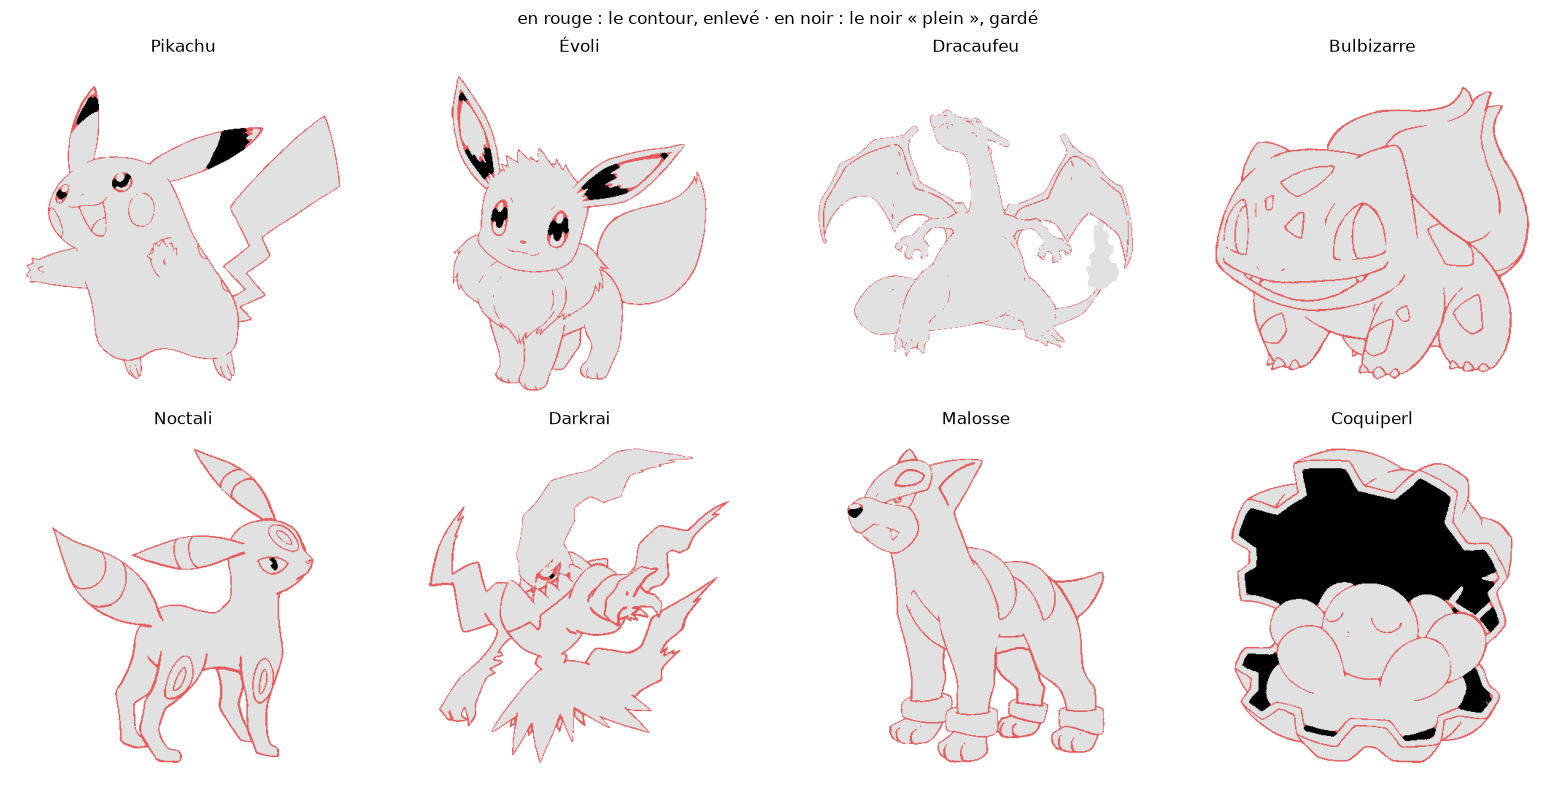

In [14]:
L_CONTOUR = 15          # un pixel « très sombre » : L* < 15
RAYON_OUVERTURE = 3     # épaisseur enlevée puis remise par l'ouverture (en pixels)
L_FRANGE = 30           # bord adouci du trait : pixel collé au trait et encore sombre

def structure(rayon):
    return ndimage.iterate_structure(ndimage.generate_binary_structure(2, 1), rayon)

def masques(d, rayon=RAYON_OUVERTURE, frange=True):
    # renvoie l'image, le masque des pixels visibles, le masque du contour et le masque du noir « plein »
    arr = np.asarray(Image.open(IMG / f"{d}.png").convert("RGBA"))
    vis = arr[..., 3] >= SEUIL_ALPHA
    L = rgb_vers_lab(arr[..., :3])[..., 0]
    sombre = vis & (L < L_CONTOUR)
    plein = ndimage.binary_opening(sombre, structure=structure(rayon))
    trait = sombre & ~plein
    if frange:
        # le bord du trait est adouci : les pixels juste à côté sont un mélange de noir et de la couleur voisine
        trait = trait | (ndimage.binary_dilation(trait) & vis & (L < L_FRANGE) & ~plein)
    return arr, vis, trait, plein

def montre(d, ax):
    arr, vis, trait, plein = masques(d)
    img = np.full(vis.shape + (3,), 255, np.uint8)
    img[vis] = (225, 225, 225); img[trait] = (230, 90, 90); img[plein] = (0, 0, 0)
    ax.imshow(img); ax.set_title(nom[d]); ax.axis("off")

ex_contour = [25, 133, 6, 1, 197, 491, 228, 366]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, d in zip(axes.ravel(), ex_contour):
    montre(d, ax)
fig.suptitle("en rouge : le contour, enlevé · en noir : le noir « plein », gardé")
plt.tight_layout(); plt.show()

Sur les exemples, la séparation marche bien :
- chez **Pikachu**, le bout des oreilles, les yeux et le nez sont gardés, tout le trait est enlevé ;
- chez **Évoli**, les ombres très foncées de l'intérieur des oreilles et les yeux sont gardés : ce sont de vraies zones sombres du dessin ;
- **Coquiperl** garde tout l'intérieur noir de sa coquille ;
- **Dracaufeu et Bulbizarre** n'ont pas de vraie zone noire : on enlève seulement leur trait ;
- chez **Noctali, Darkrai et Malosse**, le corps « noir » est en fait un gris très foncé (L\* autour de 30) : il n'est pas assez sombre pour être pris pour un trait, donc il n'est pas touché. Seuls leurs yeux ou leur nez sont du noir « plein ».

In [15]:
# le choix du rayon : est-ce que le résultat en dépend beaucoup ? (sur les 1 025 Pokémon, sans le bord adouci)
lignes = []
for rayon in [2, 3, 4]:
    for d in infos.index:
        _, vis, trait, plein = masques(d, rayon, frange=False)
        lignes.append({"rayon": rayon, "dex": d, "part_trait": trait.sum() / vis.sum(), "part_noir_plein": plein.sum() / vis.sum()})
sens = pd.DataFrame(lignes)
resume_rayon = sens.groupby("rayon").agg(trait_median=("part_trait", "median"), noir_plein_median=("part_noir_plein", "median"),
                                          noir_plein_5pc=("part_noir_plein", lambda x: int((x >= 0.05).sum())))
large = sens.pivot(index="dex", columns="rayon", values="part_noir_plein")
print("corrélation (Spearman) de la part de noir plein entre rayons :",
      round(large[2].corr(large[3], method="spearman"), 3), "(2 et 3) |", round(large[3].corr(large[4], method="spearman"), 3), "(3 et 4)")
resume_rayon.round(3)

corrélation (Spearman) de la part de noir plein entre rayons : 0.916 (2 et 3) | 0.954 (3 et 4)


,trait_median,noir_plein_median,noir_plein_5pc
rayon,,,
2,0.063,0.0,62
3,0.063,0.0,57
4,0.064,0.0,54


Le résultat dépend très peu du rayon : la part de contour est la même (6,3 % du corps en médiane), le nombre de Pokémon qui ont au moins 5 % de noir « plein » bouge à peine (62, 57, 54), et la part de noir plein d'un Pokémon est presque la même d'un rayon à l'autre (Spearman 0,92 et 0,95). Ce n'est donc pas un réglage fragile. On garde **un rayon de 3 pixels** : un trait du dessin fait quelques pixels d'épaisseur, et le rayon du milieu évite les deux extrêmes.

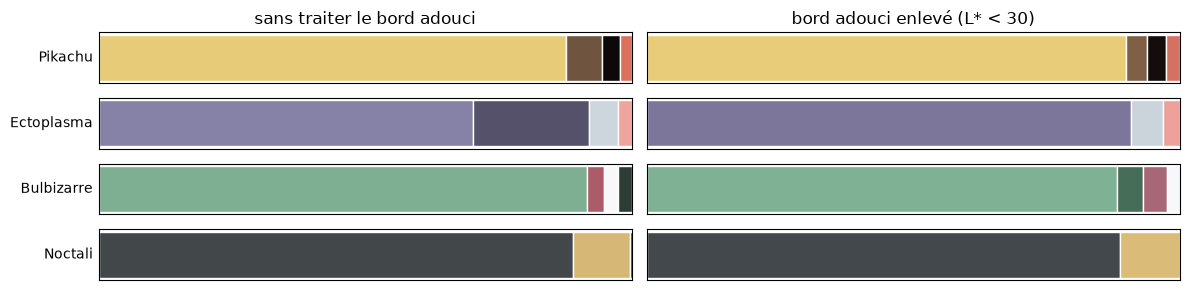

In [16]:
# le bord adouci du trait : sans le traiter, il laisse de fausses couleurs sombres
def palette_sans_contour(d, frange=True):
    arr, vis, trait, plein = masques(d, frange=frange)
    X = arr[..., :3][vis & ~trait].astype(float)
    if len(X) > N_PIXELS:
        X = X[np.random.default_rng([SEED, d]).choice(len(X), N_PIXELS, replace=False)]
    c, p, lab = palette(X)
    fc, fp, rang = fusion(c, p, FUSION_DELTA_E)
    return fc, fp, X, rang[lab], trait.sum() / vis.sum()

ex_frange = [25, 94, 1, 197]
fig, axes = plt.subplots(len(ex_frange), 2, figsize=(12, 0.6 * len(ex_frange) + 0.6))
for ligne, d in zip(axes, ex_frange):
    for ax, fr in zip(ligne, [False, True]):
        fc, fp, *_ = palette_sans_contour(d, fr)
        dessine(ax, fc, fp); ax.set_xticks([])
    ligne[0].set_ylabel(nom[d], rotation=0, ha="right", va="center")
axes[0, 0].set_title("sans traiter le bord adouci"); axes[0, 1].set_title(f"bord adouci enlevé (L* < {L_FRANGE})")
plt.tight_layout(); plt.show()

Il reste un détail : le trait est **adouci** sur ses bords (comme les bords du Pokémon avec le fond). Les pixels juste à côté du trait sont un mélange de noir et de la couleur voisine, assez sombre mais pas assez pour passer sous L\* = 15. Si on les laisse, ils forment de **fausses couleurs** : Ectoplasma est coupé en deux violets (un clair et un foncé qui n'existe que le long des traits), et le brun de Pikachu est gonflé.

On enlève donc aussi, avec le contour, **les pixels collés au trait (1 pixel autour) s'ils sont encore sombres (L\* < 30)**. Ectoplasma retrouve un seul violet, et le brun de Pikachu retombe à 4 %, ce qui correspond à ses vraies rayures sur le dos. On a choisi 30 parce que c'est juste sous le corps des Pokémon les plus sombres (Noctali, Darkrai, vers 30) : comme on n'enlève qu'une bande d'un pixel le long du trait, leur corps reste. Bulbizarre garde un vert foncé, qui correspond à ses vraies taches.

## 5. Le k-means sur les 1 025 Pokémon, sans le contour

On applique tout à chaque Pokémon : on enlève le contour de l'image, on tire 3 000 pixels parmi ceux qui restent (toujours un tirage par Pokémon), puis k-means (k = 8) et fusion des nuances (ΔE < 25).

In [17]:
nettoye, part_trait, part_noir = {}, {}, {}
for d in infos.index:
    fc, fp, X, groupe, pt = palette_sans_contour(d)
    nettoye[d] = (fc, fp, X.astype(np.uint8), pt)
    part_trait[d] = pt
    _, vis, _, plein = masques(d)
    part_noir[d] = plein.sum() / vis.sum()
part_trait, part_noir = pd.Series(part_trait), pd.Series(part_noir)
print(f"part du corps enlevée comme contour : médiane {part_trait.median():.1%}, de {part_trait.min():.1%} à {part_trait.max():.1%}")
print(f"noir « plein » gardé : {(part_noir > 0).sum()} Pokémon en ont, {(part_noir >= 0.05).sum()} en ont au moins 5 % du corps")
pd.DataFrame({"nom_fr": nom, "couleur_officielle": table.couleur, "noir_plein": part_noir.round(3), "contour": part_trait.round(3)}) \
  .sort_values("noir_plein", ascending=False).head(12)

part du corps enlevée comme contour : médiane 8.7%, de 0.0% à 25.8%
noir « plein » gardé : 406 Pokémon en ont, 57 en ont au moins 5 % du corps


,nom_fr,couleur_officielle,noir_plein,contour
366,Coquiperl,blue,0.371,0.056
262,Grahyèna,gray,0.345,0.111
800,Necrozma,black,0.318,0.160
140,Kabuto,brown,0.257,0.069
362,Oniglali,gray,0.207,0.062
92,Fantominus,purple,0.205,0.047
838,Wagomine,black,0.195,0.194
844,Dunaconda,green,0.195,0.048
897,Spectreval,black,0.193,0.102
949,Terracruel,black,0.190,0.090


Le contour (trait et bord adouci) couvre **8,7 % du corps en médiane**, jusqu'à 26 % chez les Pokémon très détaillés et sombres (Malamandre). **406 Pokémon** ont un peu de noir « plein » (souvent juste les yeux), et **57 en ont au moins 5 % du corps**, assez pour compter comme une vraie couleur : l'intérieur de la coquille de Coquiperl, le pelage de Grahyèna, le corps de Necrozma, le dessous de Kabuto, le visage d'Oniglali… Avec la première version de la règle, ces zones noires étaient soit enlevées avec le contour, soit gardées avec le contour collé dessus.

Sur les palettes ci-dessous (avec et sans le contour), les Pokémon perdent leur bande noire de contour et gardent leurs vraies couleurs. Pikachu et Évoli gardent un petit noir (oreilles, yeux), Noctali, Darkrai, Malosse et Corvaillus gardent leur grande zone sombre.

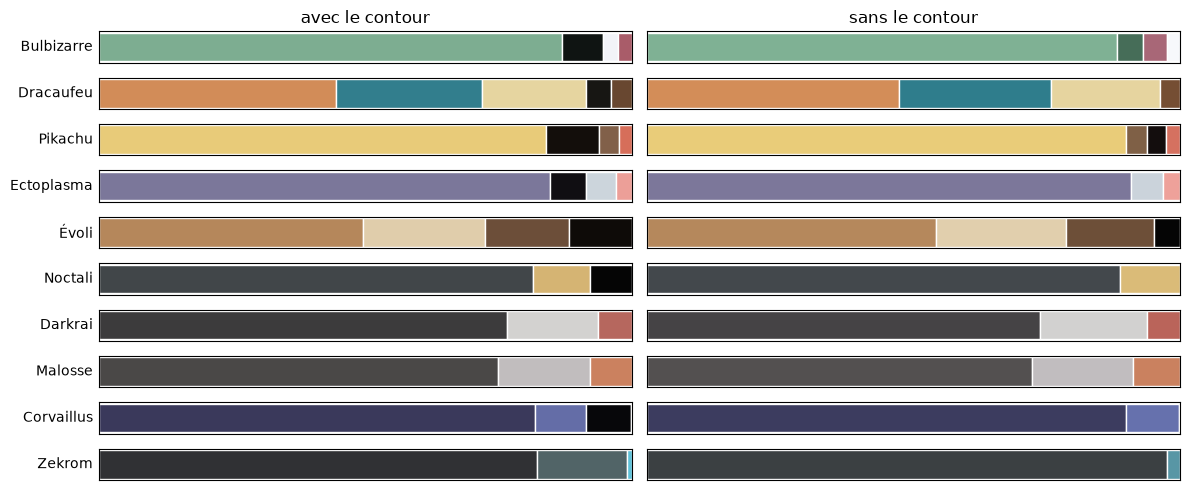

In [18]:
# avant / après sur quelques exemples : palette avec le contour (k-means sur tous les pixels) et sans
ex = [1, 6, 25, 94, 133, 197, 491, 228, 823, 644]
fig, axes = plt.subplots(len(ex), 2, figsize=(12, 0.45 * len(ex) + 0.5))
for ligne, d in zip(axes, ex):
    c, p, _ = palette(pixels(d))
    fc, fp, _ = fusion(c, p, FUSION_DELTA_E)
    dessine(ligne[0], fc, fp)
    dessine(ligne[1], nettoye[d][0], nettoye[d][1])
    ligne[0].set_ylabel(nom[d], rotation=0, ha="right", va="center")
    for ax in ligne: ax.set_xticks([])
axes[0, 0].set_title("avec le contour"); axes[0, 1].set_title("sans le contour")
plt.tight_layout(); plt.show()

In [19]:
# vérification sur les 51 Pokémon de couleur officielle noire : est-ce qu'il leur reste une couleur sombre ?
verif = pd.DataFrame({
    "contour": part_trait,
    "L_min_apres": pd.Series({d: rgb_vers_lab(v[0])[:, 0].min() for d, v in nettoye.items()}),
    "part_sombre_apres": pd.Series({d: v[1][rgb_vers_lab(v[0])[:, 0] < 35].sum() for d, v in nettoye.items()}),
}).join(table[["nom_fr", "couleur"]])
vn = verif[verif.couleur == "black"]
print("gardent une couleur sombre (L* < 35) d'au moins 5 % du corps :", (vn.part_sombre_apres >= 0.05).sum(), "sur", len(vn))
vn[vn.part_sombre_apres < 0.05].round(3)

gardent une couleur sombre (L* < 35) d'au moins 5 % du corps : 35 sur 51


,contour,L_min_apres,part_sombre_apres,nom_fr,couleur
143,0.053,50.324,0.000,Ronflex,black
215,0.111,41.386,0.000,Farfuret,black
303,0.087,40.535,0.000,Mysdibule,black
325,0.077,2.850,0.009,Spoink,black
336,0.080,42.184,0.000,Séviper,black
354,0.097,53.674,0.000,Branette,black
355,0.052,3.812,0.019,Skelénox,black
356,0.086,36.369,0.000,Téraclope,black
446,0.061,51.979,0.000,Goinfrex,black
461,0.098,48.885,0.000,Dimoret,black


Sur les 51 Pokémon de couleur officielle noire, **35 gardent une couleur sombre** qui couvre au moins 5 % du corps. Les 16 autres sont de deux sortes :
- des Pokémon dont le « noir » officiel n'est pas la couleur qui couvre le plus de surface (Ronflex est surtout bleu-vert et crème, Goinfrex aussi, Séviper, Mysdibule…) ;
- des Pokémon dont le corps « noir » est en fait un **gris foncé** (L\* de 36 à 49 : Dimoret, Noctunoir, Zébibron, Malamandre). Avec la première version de la règle, ils gardaient une couleur sombre parce que les pixels du contour se mélangeaient à leur corps dans le k-means et le faisaient paraître plus noir. Ce n'est donc pas une erreur de la nouvelle méthode, c'est plutôt l'ancienne qui les assombrissait.

### Ce qu'on a fait et pourquoi

**1. Séparer le contour du noir par la forme, pas par la couleur.** Le contour et les vraies zones noires (bout des oreilles de Pikachu, coquille de Coquiperl…) ont la même couleur : une règle sur la couleur ne peut pas les séparer. Une première version enlevait la couleur la plus sombre après le k-means si elle couvrait peu du corps ; elle enlevait les oreilles de Pikachu avec le contour, gardait le contour des Pokémon très noirs, et faisait basculer certains Pokémon (Malosse) selon les pixels tirés. Ce qui distingue vraiment un contour, c'est d'être un **trait fin** : on a donc travaillé sur l'image, avant le k-means.

**2. L'ouverture morphologique.** On érode le masque des pixels très sombres (les traits fins disparaissent), puis on le dilate (les taches pleines reviennent à leur taille). C'est une méthode classique de traitement d'image, hors cours, simple à expliquer et qui ne dépend que d'un réglage (le rayon).

**3. Vérifier que le réglage ne compte pas trop.** On a refait le calcul avec trois rayons sur les 1 025 Pokémon : les résultats bougent très peu, donc le choix du rayon n'est pas décisif.

**4. Traiter le bord adouci.** En regardant les palettes, on a vu de fausses couleurs sombres le long des traits (Ectoplasma coupé en deux violets). On enlève donc aussi le pixel collé au trait s'il est encore sombre, avec un seuil (L\* < 30) choisi pour ne pas toucher au corps des Pokémon les plus sombres.

**5. Regarder les images, pas seulement les chiffres.** Pour chaque étape, on a affiché le contour (en rouge) et le noir gardé (en noir) sur des Pokémon choisis exprès (clairs, sombres, avec du vrai noir), puis vérifié les Pokémon de couleur officielle noire un par un. C'est comme ça qu'on a compris que certains « noirs » sont en fait des gris foncés.

**Limite :** les détails noirs très fins (rayures fines, moustaches) partent avec le contour, puisqu'on ne peut pas les distinguer d'un trait.

## 6. Les variables de couleur de chaque Pokémon

Maintenant qu'on a la palette de chaque Pokémon sans le contour, on peut calculer les variables. Il reste à décider à partir de quelle part du corps une couleur compte comme « importante ». On regarde ce que donne le nombre de couleurs avec plusieurs seuils.

In [20]:
for s in [0.02, 0.05, 0.10]:
    nb = pd.Series({d: int((v[1] >= s).sum()) for d, v in nettoye.items()})
    print(f"seuil {s:.0%} : médiane {nb.median():.0f} couleurs, de {nb.min()} à {nb.max()} ; répartition {nb.value_counts().sort_index().to_dict()}")

seuil 2% : médiane 4 couleurs, de 1 à 8 ; répartition {1: 5, 2: 135, 3: 305, 4: 296, 5: 192, 6: 71, 7: 18, 8: 3}
seuil 5% : médiane 3 couleurs, de 1 à 8 ; répartition {1: 42, 2: 277, 3: 378, 4: 210, 5: 85, 6: 25, 7: 7, 8: 1}
seuil 10% : médiane 2 couleurs, de 1 à 6 ; répartition {1: 106, 2: 422, 3: 368, 4: 107, 5: 21, 6: 1}


Le seuil change beaucoup le résultat :
- à **2 %**, on compte jusqu'à 8 couleurs, mais on compte aussi des petits détails (les yeux, une griffe, un reflet) ;
- à **10 %**, 106 Pokémon n'ont plus qu'une couleur et 422 en ont deux : on perd des couleurs secondaires bien visibles sur les dessins ;
- à **5 %**, on a entre 1 et 8 couleurs, 3 en médiane, ce qui correspond à ce qu'on voit à l'œil sur les exemples.

On choisit donc **5 %** : une couleur compte comme « importante » si elle couvre au moins 5 % du corps (sans le contour).

In [21]:
PART_MIN = 0.05

lignes = []
for d, (centres, parts, pix, contour) in nettoye.items():
    r, g, b = centres[0]
    h, s, v = colorsys.rgb_to_hsv(r / 255, g / 255, b / 255)
    hsv = np.array([colorsys.rgb_to_hsv(*(p / 255)) for p in pix])
    lignes.append({
        "dex": d,
        "nb_couleurs": int((parts >= PART_MIN).sum()),
        "dom_r": round(r), "dom_v": round(g), "dom_b": round(b),
        "dom_hex": "#{:02x}{:02x}{:02x}".format(round(r), round(g), round(b)),
        "dom_teinte": round(h * 360, 1), "dom_saturation": round(s, 3), "dom_luminosite": round(v, 3),
        "dom_part": round(parts[0], 3),
        "saturation_moyenne": round(hsv[:, 1].mean(), 3), "luminosite_moyenne": round(hsv[:, 2].mean(), 3),
        "palette": ";".join("#{:02x}{:02x}{:02x}:{:.3f}".format(*np.round(c).astype(int), p) for c, p in zip(centres, parts)),
    })
coul = pd.DataFrame(lignes).set_index("dex")
coul.head()

,nb_couleurs,dom_r,dom_v,dom_b,dom_hex,dom_teinte,dom_saturation,dom_luminosite,dom_part,saturation_moyenne,luminosite_moyenne,palette
dex,,,,,,,,,,,,
1,2,127,177,148,#7fb194,145.0,0.282,0.692,0.881,0.287,0.685,#7fb194:0.881;#466d58:0.050;#a86777:0.044;#f7f...
2,4,112,168,179,#70a8b3,189.2,0.374,0.700,0.491,0.368,0.664,#70a8b3:0.491;#689579:0.282;#ce7783:0.131;#386...
3,5,89,150,150,#599696,180.2,0.407,0.589,0.380,0.375,0.618,#599696:0.380;#ce7378:0.210;#698c65:0.179;#465...
4,2,211,156,119,#d39c77,24.3,0.438,0.828,0.625,0.381,0.840,#d39c77:0.625;#eadbc6:0.257;#e17745:0.038;#634...
5,2,206,109,92,#ce6d5c,8.8,0.553,0.808,0.695,0.458,0.820,#ce6d5c:0.695;#dcc7bb:0.241;#f8d170:0.038;#754...


In [22]:
coul[["nb_couleurs", "dom_part", "dom_saturation", "dom_luminosite", "saturation_moyenne", "luminosite_moyenne"]].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
nb_couleurs,1025.0,3.124,1.144,1.000,2.000,3.000,4.000,8.000
dom_part,1025.0,0.584,0.173,0.221,0.461,0.557,0.695,1.000
dom_saturation,1025.0,0.293,0.213,0.000,0.105,0.266,0.458,0.992
dom_luminosite,1025.0,0.707,0.208,0.022,0.574,0.762,0.877,0.996
saturation_moyenne,1025.0,0.302,0.142,0.011,0.193,0.295,0.405,0.801
luminosite_moyenne,1025.0,0.702,0.127,0.252,0.619,0.713,0.796,0.961


Sans le contour, un Pokémon a en moyenne **3,1 couleurs importantes** (médiane 3, de 1 à 8), et sa couleur dominante couvre en moyenne 58 % du corps. Enlever le contour change surtout le nombre de couleurs et la luminosité moyenne (on retire beaucoup de pixels noirs), et un peu la couleur dominante des Pokémon sombres : avec le contour, ses pixels se mélangeaient à leur corps et le faisaient paraître plus noir.

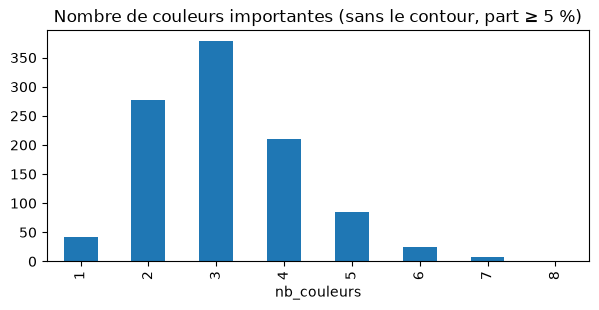

In [23]:
coul["nb_couleurs"].value_counts().sort_index().plot.bar(figsize=(7, 3), title="Nombre de couleurs importantes (sans le contour, part ≥ 5 %)")
plt.show()

In [24]:
tmp = coul.join(nom)
print(tmp.sort_values(["nb_couleurs", "dom_part"], ascending=[True, False]).head(8)[["nom_fr", "nb_couleurs", "dom_part"]])
print(tmp.sort_values(["nb_couleurs", "dom_part"], ascending=[False, True]).head(8)[["nom_fr", "nb_couleurs", "dom_part"]])

         nom_fr  nb_couleurs  dom_part
dex                                   
868       Crèmy            1     1.000
51   Triopikeur            1     0.996
132   Métamorph            1     0.993
980   Terraiste            1     0.983
594     Mamanbo            1     0.982
644      Zekrom            1     0.975
93     Spectrum            1     0.972
113   Leveinard            1     0.968
           nom_fr  nb_couleurs  dom_part
dex                                     
1021   Ire-Foudre            8     0.229
870      Hexadron            7     0.221
910     Crocogril            7     0.259
911    Flâmigator            7     0.268
1020  Feu-Perçant            7     0.288
658     Amphinobi            7     0.292
178          Xatu            7     0.304
982   Deusolourdo            7     0.360


Les Pokémon à une seule couleur sont des Pokémon « d'un bloc » : Crèmy, Triopikeur, Métamorph, Terraiste, Mamanbo, Zekrom. Le plus chargé est Ire-Foudre (8 couleurs), suivi de Hexadron, Crocogril, Flâmigator, Feu-Perçant, Amphinobi, Xatu et Deusolourdo (7).

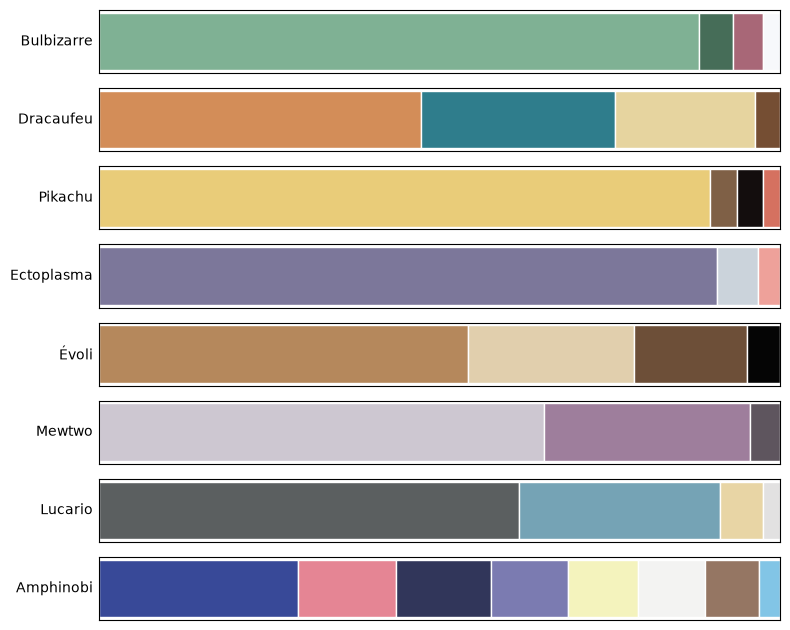

In [25]:
exemples = [1, 6, 25, 94, 133, 150, 448, 658]
fig, axes = plt.subplots(len(exemples), 1, figsize=(8, 0.8 * len(exemples)))
for ax, d in zip(axes, exemples):
    dessine(ax, nettoye[d][0], nettoye[d][1])
    ax.set_ylabel(nom[d], rotation=0, ha="right", va="center")
    ax.set_xticks([])
plt.tight_layout(); plt.show()

### Ce qu'on a fait et pourquoi

**1. Choisir le seuil de « couleur importante » en comparant plusieurs valeurs.** On a calculé le nombre de couleurs avec trois seuils de part du corps et regardé la répartition obtenue. On a gardé celui qui donne des résultats qui collent à ce qu'on voit sur les dessins : un seuil trop bas compte les yeux et les reflets, un seuil trop haut fait disparaître des couleurs secondaires bien visibles.

**2. Des variables en HSV.** Pour décrire la couleur dominante et l'ensemble du Pokémon, on a utilisé le système HSV (teinte, saturation, luminosité) en plus du code RGB. Le HSV est plus facile à interpréter : « plus saturé » ou « plus lumineux » veut dire quelque chose, alors qu'une hausse du « vert » en RGB ne dit pas grand-chose. La saturation et la luminosité moyennes sont calculées sur les pixels (sans le contour), pas sur les centres, pour tenir compte de la surface de chaque couleur.

**3. Le diagramme en barres du nombre de couleurs.** Le nombre de couleurs est un petit nombre entier, donc un diagramme en barres (une barre par valeur) est plus lisible qu'un histogramme.

## 7. Ramener la couleur dominante à une famille de couleur

Pour comparer avec la couleur officielle de PokéAPI, il faut transformer la couleur dominante (un code RGB) en un des **10 noms** utilisés par PokéAPI : black, blue, brown, gray, green, pink, purple, red, white, yellow.

On passe par le système **HSV** (teinte, saturation, luminosité), qui est plus proche de la façon dont on décrit une couleur avec des mots. Il n'existe pas de règle officielle pour passer d'un code couleur à un nom, donc on décide de faire nos propres seuils, simples, en suivant le bon sens :
- très sombre (luminosité < 0,25) → black ;
- peu saturée (saturation < 0,2) → white si claire, gray sinon ;
- les rouges et magentas clairs et pas trop saturés → pink ;
- sinon on regarde la teinte (l'angle sur le cercle des couleurs : rouge vers 0°, jaune vers 60°, vert vers 120°, bleu vers 240°…), et les teintes orangées sombres deviennent brown.

C'est une approximation : on verra en comparant avec la couleur officielle où elle se trompe.

In [26]:
def famille(h, s, v):
    h = h * 360
    if v < 0.25:
        return "black"
    if s < 0.2:
        return "white" if v > 0.8 else "gray"
    if (h >= 300 or h < 15) and s < 0.55 and v > 0.7:
        return "pink"
    if h < 15 or h >= 345:
        return "brown" if v < 0.5 else "red"
    if h < 40:
        return "brown" if (v < 0.7 or s < 0.5) else "red"
    if h < 70:
        return "brown" if v < 0.5 else "yellow"
    if h < 170:
        return "green"
    if h < 260:
        return "blue"
    if h < 290:
        return "purple"
    return "pink"

coul["famille_dominante"] = [famille(h / 360, s, v) for h, s, v in coul[["dom_teinte", "dom_saturation", "dom_luminosite"]].values]
coul["famille_dominante"].value_counts()

famille_dominante
white     204
gray      190
blue      175
brown      98
yellow     94
green      81
red        76
pink       66
black      22
purple     19
Name: count, dtype: int64

White, gray et blue sont les familles dominantes les plus fréquentes (204, 190 et 175 Pokémon). Beaucoup de Pokémon ont un corps pâle ou grisé, et les dessins ont des zones claires (reflets). Purple est presque absent (19), et black aussi (22) : sans le contour, les corps « noirs » sont surtout des gris très foncés.

In [27]:
pd.crosstab(table["couleur"], coul["famille_dominante"], margins=True)

famille_dominante,black,blue,brown,gray,green,pink,purple,red,white,yellow,All
couleur,,,,,,,,,,,
black,10,7,0,28,0,0,0,1,4,1,51
blue,2,109,2,19,1,2,1,2,29,3,170
brown,1,0,72,26,0,3,0,10,21,14,147
gray,2,13,1,61,1,2,1,0,21,5,107
green,1,14,7,9,68,2,1,5,13,10,130
pink,1,2,2,2,1,27,0,2,21,2,60
purple,2,16,0,22,3,12,16,0,15,1,87
red,2,6,3,8,0,15,0,46,7,10,97
white,0,5,0,10,3,2,0,2,65,1,88


In [28]:
accord = (table["couleur"] == coul["famille_dominante"]).mean()
print("même famille que la couleur officielle :", round(accord, 3))
(table["couleur"] == coul["famille_dominante"]).groupby(table["couleur"]).mean().sort_values().round(2)

même famille que la couleur officielle : 0.508


couleur
purple    0.18
black     0.20
pink      0.45
red       0.47
brown     0.49
green     0.52
yellow    0.53
gray      0.57
blue      0.64
white     0.74
dtype: float64

La couleur dominante calculée tombe dans la même famille que la couleur officielle pour **51 %** des Pokémon seulement. Ça marche bien pour white (74 %) et blue (64 %), très mal pour purple (18 %) et black (20 %). Les violets officiels sont souvent classés blue, gray ou pink chez nous, et les noirs officiels presque toujours gray : par exemple le corps de Noctali est un gris très foncé (luminosité 0,30), au-dessus de notre seuil de 0,25 pour black.

In [29]:
# quelques désaccords pour comprendre
des = coul.join(table[["nom_fr", "couleur"]])
des = des[des.couleur != des.famille_dominante]
des.sample(10, random_state=SEED)[["nom_fr", "couleur", "famille_dominante", "dom_hex", "dom_part"]]

,nom_fr,couleur,famille_dominante,dom_hex,dom_part
dex,,,,,
165,Coxy,red,yellow,#e1d7b3,0.626
189,Cotovol,blue,white,#e7dbb9,0.531
971,Toutombe,white,gray,#a8b0bf,0.858
717,Yveltal,red,gray,#423f49,0.508
804,Mandrillon,purple,blue,#423078,0.505
32,Nidoran♂,purple,pink,#9d769e,0.825
670,Floette,white,red,#a3464b,0.399
851,Scolocendre,red,yellow,#efb32b,0.339
318,Carvanha,red,yellow,#ddc382,0.476


Sur les exemples, deux raisons reviennent. D'abord nos seuils HSV : un violet foncé comme Mandrillon devient « blue », Nidoran♂ devient « pink » (et hors de cet échantillon, un violet pâle comme Mentali devient « white »). Ensuite, la couleur officielle n'est pas toujours la couleur qui prend le plus de place sur le dessin : Yveltal est « red » officiellement alors que son corps est gris très foncé, et Floette est « white » alors que sa plus grande zone est sa fleur rouge.

Les deux mesures ne disent donc pas la même chose : l'officielle, c'est la couleur « d'identité » choisie par les jeux ; la nôtre, c'est la couleur qui couvre le plus de surface. On garde les deux dans la suite, chacune pour ce qu'elle mesure.

### Ce qu'on a fait et pourquoi

**1. Des seuils HSV faits à la main.** Pour comparer avec la couleur officielle, il fallait transformer un code couleur en un des 10 noms de PokéAPI. Il n'existe pas de règle officielle, alors on a écrit des règles simples sur la teinte, la saturation et la luminosité. On a préféré des règles qu'on peut lire et expliquer plutôt qu'un modèle appris, parce qu'on n'a pas de « bonne réponse » fiable pour l'entraîner : la couleur officielle ne mesure pas la même chose que la nôtre.

**2. Le tableau croisé et le taux d'accord par couleur.** On a croisé la couleur officielle et notre famille dominante, et calculé le taux d'accord pour chaque couleur officielle. Le taux global seul ne suffisait pas : il cache que certaines couleurs marchent bien et d'autres très mal.

**3. Lire des désaccords au hasard.** On a tiré des désaccords au hasard (graine fixe) pour comprendre d'où ils viennent, plutôt que de regarder seulement les plus gros. Ça nous a montré que ce n'est pas qu'un problème de seuils : les deux mesures ne disent pas la même chose, donc on garde les deux.

## 8. Les couleurs selon la génération

            nb_couleurs  saturation_moyenne  luminosite_moyenne
generation                                                     
1                  2.67                0.28                0.74
2                  2.91                0.33                0.73
3                  2.74                0.27                0.76
4                  3.13                0.31                0.67
5                  3.04                0.28                0.67
6                  3.35                0.31                0.71
7                  3.55                0.28                0.69
8                  3.45                0.33                0.65
9                  3.70                0.36                0.68


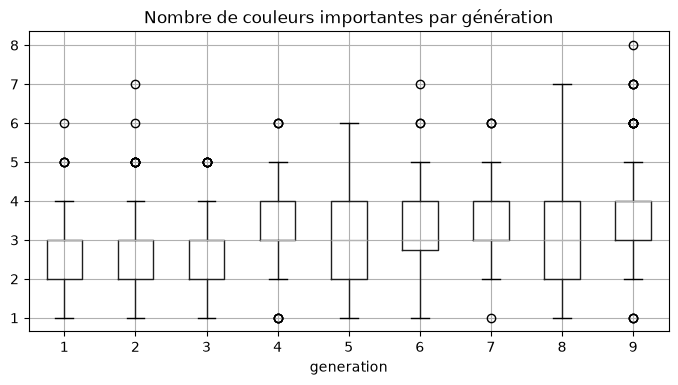

In [30]:
g = coul.join(table["generation"])
print(g.groupby("generation")[["nb_couleurs", "saturation_moyenne", "luminosite_moyenne"]].mean().round(2))
g.boxplot(column="nb_couleurs", by="generation", figsize=(8, 4))
plt.suptitle(""); plt.title("Nombre de couleurs importantes par génération"); plt.show()

Le nombre de couleurs augmente au fil des générations : **2,7 en moyenne en génération 1**, autour de **3,5-3,7 en générations 7 et 9**. La saturation moyenne monte un peu (0,28 en génération 1, 0,36 en génération 9) et la luminosité baisse (0,74 en génération 1, entre 0,65 et 0,71 à partir de la génération 4). Les Pokémon récents sont donc un peu plus chargés en couleurs, mais les écarts restent petits par rapport à la dispersion qu'on voit dans les boîtes. On testera ça proprement dans le notebook sur la conception.

### Ce qu'on a fait et pourquoi

On a comparé les générations avec la **moyenne par génération** et une **boîte à moustaches** du nombre de couleurs. La moyenne donne la tendance, et la boîte montre en plus la dispersion dans chaque génération : c'est elle qui permet de voir que les écarts entre générations sont petits par rapport aux différences entre Pokémon d'une même génération. On n'a pas fait de test ici : la question « est-ce que le design change avec les générations ? » est traitée proprement dans le notebook 06.

## 9. Export

On enregistre une ligne par Pokémon avec ses variables de couleur (sans le contour), pour les analyses suivantes (conception, réseau). On y ajoute la part du corps couverte par le contour (un indice du **niveau de détail** du dessin, utilisé dans le notebook 06) et la part de noir « plein ».

In [31]:
# la part de contour (le niveau de détail du dessin : plus il y a de traits, plus elle est grande)
# et la part de noir « plein », calculées en partie 5, servent aussi au notebook 06
coul["part_contour"] = part_trait.round(4)
coul["part_noir_plein"] = part_noir.round(4)
coul.to_csv(OUT / "couleurs_sprites.csv")
print("écrit :", OUT / "couleurs_sprites.csv", coul.shape)

écrit : ../data/processed/couleurs_sprites.csv (1025, 15)
